# Compare sensitivity tests

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from dask.distributed import Client
import intake
import cmocean as cmo
import glob, os
import cartopy.crs as ccrs
import matplotlib.path as mpath
from matplotlib import colors
import gsw
from xhistogram.xarray import histogram as xhistogram
from matplotlib import ticker, cm, colors
import pandas as pd


In [2]:
import warnings
warnings.filterwarnings(
    "ignore",
    message="The specified chunks separate the stored chunks along dimension",
    category=UserWarning
)

In [3]:
client = Client(threads_per_worker=1)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 28
Total threads: 28,Total memory: 251.19 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:34503,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:37271,Total threads: 1
Dashboard: /proxy/45619/status,Memory: 8.97 GiB
Nanny: tcp://127.0.0.1:39525,


Define experiments

In [4]:
expt_dict = {'old_control': 
                 {'path': '/g/data/ik11/outputs/access-rom3-panan/MC_4km_jra_iaf+regionalpanan+isf/',
                  'details': 'old version of model run in Q1 2026',
                  'relevant_control': None,
                  'github_issue': None
                 },
             'new_control': 
                 {'path': '/scratch/oz91/akm157/access-om3/archive/access-rom3-panan4km-iceshelf/',
                  'details': 'updated model with new ICs, B-grid coastlines, MOM update, iceberg spreading (incl. bug, fixed after a few months)',
                  'relevant_control': 'old_control',
                  'github_issue': 'https://github.com/claireyung/mom6-panAn-iceshelf-tools/issues/61'
                 },
             'old_no_icb_latent': 
                 {'path': '/scratch/oz91/fbd581/access-om3/archive/access-om3-configs/', ## FABIO,
                  'details': 'old control with latent heat from icebergs switched off', 
                  'relevant_control': 'old_control',
                  'github_issue':'https://github.com/claireyung/mom6-panAn-iceshelf-tools/issues/80'},
             # 'no_icb_latent': 
             #     {'path': scratch bye bye,
             #      'details': 'New config but iceberg LH turned off', 
             #      'relevant_control': 'new_control',
             #      'github_issue': 'https://github.com/claireyung/mom6-panAn-iceshelf-tools/issues/61'},
             'ERA5_wind': 
                 {'path':'/scratch/oz91/akm157/access-om3/archive/access-rom3-panan4km-iceshelf_ERA5_wind/' ,
                  'details': 'Perturb winds in Amundsen region to match ERA5', 
                  'relevant_control': 'new_control',
                  'github_issue':'https://github.com/claireyung/mom6-panAn-iceshelf-tools/issues/74'},
             'Yamazaki_initial_conditions': 
                 {'path': '/scratch/oz91/jn8053/access-om3/archive/access-rom3-panan4km-iceshelf/',
                  'details': 'Starting from old, Yamazaki-based initial conditions', 
                  'relevant_control': 'new_control',
                  'github_issue':'https://github.com/claireyung/mom6-panAn-iceshelf-tools/issues/64'},
             'seasonal_icebergs': 
                 {'path': '/scratch/oz91/akm157/access-om3/archive/access-rom3-panan4km-iceshelf_seasonal_icebergs/',
                  'details': 'fix iceberg spreading seasonality', 
                  'relevant_control': 'new_control',
                  'github_issue': 'https://github.com/claireyung/mom6-panAn-iceshelf-tools/issues/73'},
             '1980_start': 
                 {'path': '/scratch/oz91/akm157/access-om3/archive/access-rom3-panan4km-iceshelf_1980_start/',
                  'details': 'compare to 1975 start', 
                  'relevant_control': 'new_control',
                  'github_issue': 'https://github.com/claireyung/mom6-panAn-iceshelf-tools/issues/66'},
             'lower_drag_coeff': 
                 {'path': '/scratch/oz91/akm157/access-om3/archive/access-rom3-panan4km-iceshelf_lower_cd/',
                  'details': 'lower drag coeff from 0.009 to 0.007', 
                  'relevant_control': 'new_control',
                  'github_issue': 'https://github.com/claireyung/mom6-panAn-iceshelf-tools/issues/67'},
             'smoothed_icebergs_from_rest': 
                 {'path': '/scratch/oz91/akm157/access-om3/archive/access-rom3-panan4km-iceshelf_smooth-icebergs/',
                  'details': 'Fixed iceberg pattern from start', 
                  'relevant_control': 'new_control',
                  'github_issue': 'https://github.com/claireyung/mom6-panAn-iceshelf-tools/issues/59'},
             'salt_rest_Amundsen': 
                 {'path': '/scratch/oz91/wf4500/access-om3/archive/ShelfRestoring/' ,
                  'details': 'Salt restoring to Zhou 2026 (bias corrected from WOA) in Amundsen region, max deltaSSS = 1', 
                  'relevant_control': 'new_control',
                  'github_issue': 'https://github.com/claireyung/mom6-panAn-iceshelf-tools/issues/75'},
             'BearRidge_SI_only': 
                 {'path': '/scratch/oz91/akm157/access-om3/archive/access-rom3-panan4km-iceshelf_bear_ridge_seaice_only/',
                  'details': 'Bear Ridge grounded iceberg land mask added to sea ice only', 
                  'relevant_control': 'new_control',
                  'github_issue': 'https://github.com/claireyung/mom6-panAn-iceshelf-tools/issues/77'},
             'BearRidge_all': 
                 {'path': '/scratch/oz91/akm157/access-om3/archive/access-rom3-panan4km-iceshelf_bear_ridge/',
                  'details': 'Bear Ridge grounded iceberg land mask added to sea ice and ocean', 
                  'relevant_control': 'new_control',
                  'github_issue': 'https://github.com/claireyung/mom6-panAn-iceshelf-tools/issues/77'},
             'BearRidge_full_salt_rest': 
                 {'path': '/scratch/oz91/wf4500/access-om3/archive/Restoring_Bear_Ridge/',
                  'details': 'BearRidge_all plus salinity restoring circumpolarly, max deltaSSS = 0.5', 
                  'relevant_control': 'new_control',
                  'github_issue': 'https://github.com/claireyung/mom6-panAn-iceshelf-tools/issues/75'},
             'sea_ice_atm_drag': 
                 {'path': '/scratch/oz91/fbd581/access-om3/archive/access-rom3-panan4km-iceshelf_bear_ridge_seaice_only/',
                  'details': 'BearRidge_SI_only plus reduced sea ice atmos drag', 
                  'relevant_control': 'new_control',
                   'github_issue': 'https://github.com/claireyung/mom6-panAn-iceshelf-tools/issues/80'},
         
                 }     

In [5]:
for expts in expt_dict.keys():
    print(expts)

old_control
new_control
old_no_icb_latent
ERA5_wind
Yamazaki_initial_conditions
seasonal_icebergs
1980_start
lower_drag_coeff
smoothed_icebergs_from_rest
salt_rest_Amundsen
BearRidge_SI_only
BearRidge_all
BearRidge_full_salt_rest
sea_ice_atm_drag


### Goal:

- make plots of
- 1. ~~total melt rate as a function of time in each region~~
  2. map of melt rate compared to control
  3. ~~timeseries of bottom temperature~~
  4. sea ice production
- ~~bar chart for Pine Island, Getz, Dotson-Crosson, Thwaites mass fluxes compared to satellite obs~~
- ~~% melt increase in Amundsen for each year in a table~~

# Plot mass flux in each region

In [6]:
def load_mass_flux(expt):
    base_path = expt_dict[expt]['path']+'output*/access-om3.mom6.2d.mass_flux.1mon.mean.*.nc'
    mass_flux = xr.open_mfdataset(glob.glob(base_path),decode_timedelta = True,
                                 chunks = {'time':1,'xT':1024,'yT':500})
    return mass_flux

In [7]:
domains = {'Amundsen sector':
           {'xslice' : slice(-150,-95),
            'yslice' : slice(-78,-72)},
           'Bellingshausen sector':
           {'xslice' : slice(-95,-55),
            'yslice' : slice(-75,-60)},
           'Filchner-Ronne':
           {'xslice' : slice(-90,-30),
            'yslice' : slice(-90,-75)},
            'Dronning Maud Land':
           {'xslice' : slice(-30,55),
            'yslice' : slice(-78,-65)},
            'Amery':
           {'xslice' : slice(55,80),
            'yslice' : slice(-75,-65)},
            'Adelie sector':
           {'xslice' : slice(-280,-190),
            'yslice' : slice(-75,-64)},
            'Ross':
           {'xslice' : slice(-210,-146),
            'yslice' : slice(-90,-75)},
}

In [18]:
def plot_total_melt_timeseries_regions(expt):

    mass_flux_control = load_mass_flux(expt_dict[expt]['relevant_control'])
    mass_flux_new = load_mass_flux(expt)
    
    # melt rate for different regions
    
    fig, axes = plt.subplots(figsize = (10,4),dpi = 300)
    s_to_yr = 365*24*60*60
    
    ax_inset = plt.axes([0.5,0.4,0.5,0.5],projection=ccrs.SouthPolarStereo())
    ax_inset.set_extent([-180, 180, -90, -65], ccrs.PlateCarree())
    ax_inset.coastlines()
    ax_inset.axis('off')
    
    # plot new sim
    for i in np.arange(7):
        domain = ['Amundsen sector','Bellingshausen sector',
                  'Filchner-Ronne','Dronning Maud Land',
                  'Amery','Adelie sector','Ross'][i]
        colors = ['C0','C1','C2','C3','C4','C5','C6','C7'][i]
        mass_flux1 = (mass_flux_control).mass_flux.sel(xT = domains[domain]['xslice'],
                         yT = domains[domain]['yslice'],
                                                      time = slice('1975-01-01','1985-01-01')).sum(['xT','yT'])/1e12*s_to_yr
        axes.plot(np.arange(len(mass_flux1))/12,mass_flux1.values,label = expt_dict[expt]['relevant_control']+ ' '+ domain,
                  color = colors, ls ='--', alpha = 0.5)
        # mass_flux1 = (mass_flux_control).mass_flux.isel(time = np.arange(60,12*39)).sel(xT = domains[domain]['xslice'],
        #                  yT = domains[domain]['yslice']).sum(['xT','yT'])/1e12*s_to_yr
        # mass_flux1 = mass_flux1.groupby('time.year').mean('time')
        # ax[1].plot(np.arange(5,len(mass_flux1)+5),mass_flux1.values,color = colors, ls ='--', alpha = 0.5)
        mass_flux_mask = (mass_flux_control).mass_flux.sel(xT = domains[domain]['xslice'],
                         yT = domains[domain]['yslice']).isel(time = 0)
        mass_flux_mask = mass_flux_mask.where(mass_flux_mask!=0)
        mass_flux_mask = mass_flux_mask*0+1
        ax_inset.contourf(mass_flux_mask.xT,mass_flux_mask.yT,mass_flux_mask,
                            levels = [0.5,1.5], colors = colors, transform=ccrs.PlateCarree())
        if i == 0:
            yearly_control = mass_flux1.groupby('time.year')
            yearly_arr = np.zeros(5)
            for j in np.arange(5):
                if yearly_control.count().isel(year = j) ==12:
                    yearly_arr[j] = yearly_control.mean('time').isel(year = j).values
                else:
                    yearly_arr[j] = np.nan
    
    for i in np.arange(7):
        domain = ['Amundsen sector','Bellingshausen sector',
                  'Filchner-Ronne','Dronning Maud Land',
                  'Amery','Adelie sector','Ross'][i]
        colors = ['C0','C1','C2','C3','C4','C5','C6','C7'][i]
        mass_flux2 = (mass_flux_new).mass_flux.sel(xT = domains[domain]['xslice'],
                         yT = domains[domain]['yslice']).sum(['xT','yT'])/1e12*s_to_yr
        axes.plot(np.arange(len(mass_flux2))/12,mass_flux2,label = expt + ' '+ domain,
                  color = colors, ls ='-')
        if i == 0:
            yearly_pert = mass_flux2.groupby('time.year')
            yearly_arr_pert = np.zeros(5)
            for j in np.arange(5):
                try:
                    if yearly_pert.count().isel(year = j) ==12:
                        yearly_arr_pert[j] = yearly_pert.mean('time').isel(year = j).values
                    else:
                        yearly_arr_pert[j] = np.nan
                except IndexError:
                    yearly_arr_pert[j] = np.nan
    
    axes.legend(loc = 'upper left', ncol = 1, bbox_to_anchor = (1.3,1))
    
    axes.set_xlabel('Time (years)')
    axes.set_ylabel('Basal melting \nmass flux (Gt/yr)')
    axes.set_title('Compare '+expt+' and '+ expt_dict[expt]['relevant_control'], fontsize = 14)
    axes.grid()
    axes.set_xlim(-0.1,5)
    
    
    fig.subplots_adjust(wspace = 0.01)
    plt.show()

    percent_incr_melt_amundsen = (yearly_arr_pert - yearly_arr)/yearly_arr * 100
    print('Amundsen melt increase wrt control, ',expt)
    print('year       1      2      3      4     5    ')
    print(np.round(percent_incr_melt_amundsen,decimals=2))
    return np.round(percent_incr_melt_amundsen,decimals=2), yearly_arr_pert, yearly_arr

In [19]:
inner_keys = ['percent_incr', 'yearly_Amundsen_pert', 'yearly_Amundsen_control']

result_dict = {
    expt: {i_key: None for i_key in inner_keys} 
    for expt in expt_dict.keys()
}

result_dict

{'old_control': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 'new_control': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 'old_no_icb_latent': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 'ERA5_wind': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 'Yamazaki_initial_conditions': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 'seasonal_icebergs': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 '1980_start': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 'lower_drag_coeff': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 'smoothed_icebergs_from_rest': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control'

Now doing new_control


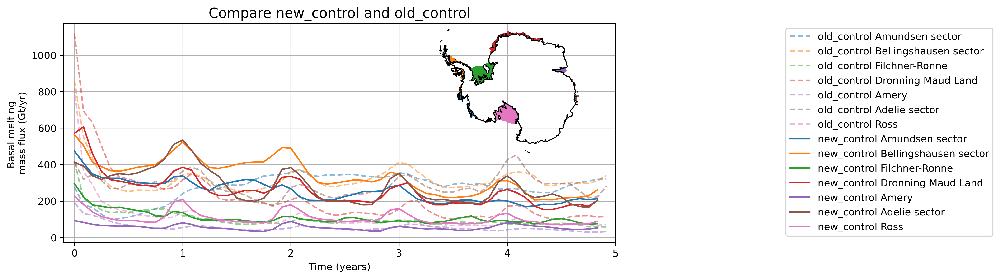

Amundsen melt increase wrt control,  new_control
year       1      2      3      4     5    
[   nan   2.19 -31.51 -28.61 -30.44]
Now doing old_no_icb_latent


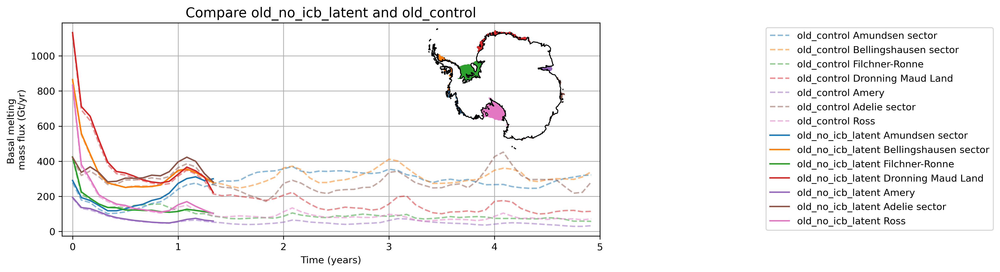

Amundsen melt increase wrt control,  old_no_icb_latent
year       1      2      3      4     5    
[10.75   nan   nan   nan   nan]
Now doing ERA5_wind


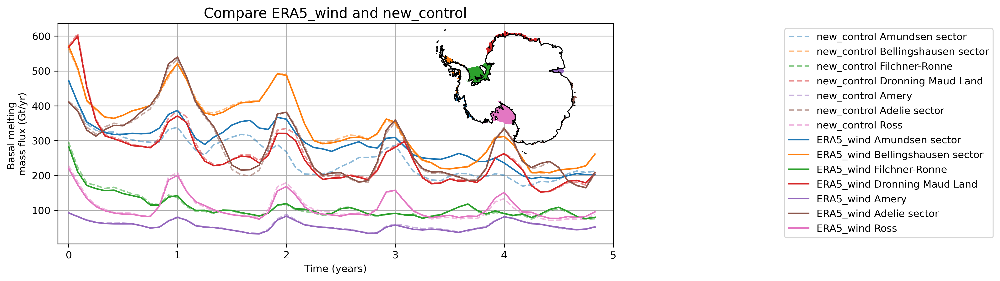

Amundsen melt increase wrt control,  ERA5_wind
year       1      2      3      4     5    
[  nan 13.13 27.58 21.55  6.83]
Now doing Yamazaki_initial_conditions


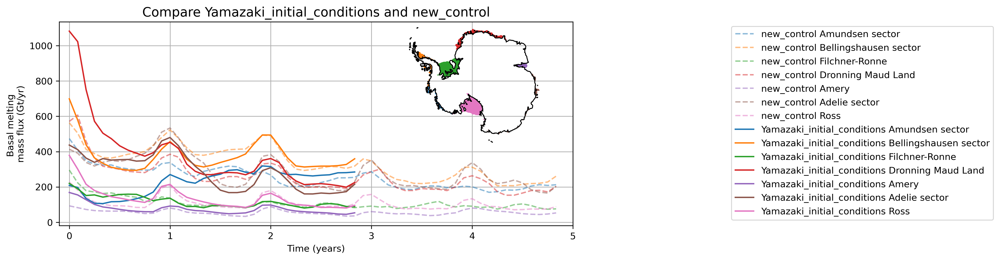

Amundsen melt increase wrt control,  Yamazaki_initial_conditions
year       1      2      3      4     5    
[   nan -12.67  19.36    nan    nan]
Now doing seasonal_icebergs


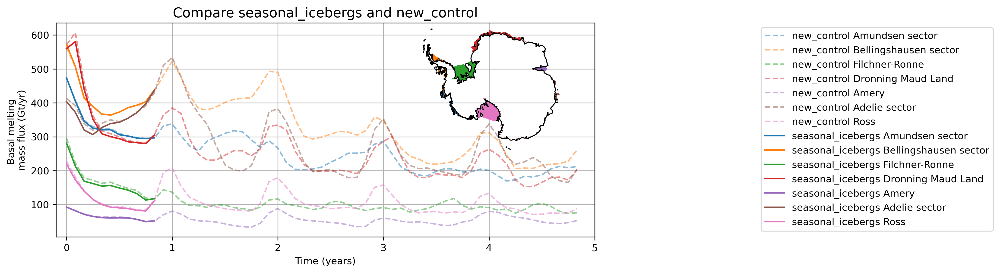

Amundsen melt increase wrt control,  seasonal_icebergs
year       1      2      3      4     5    
[nan nan nan nan nan]
Now doing 1980_start


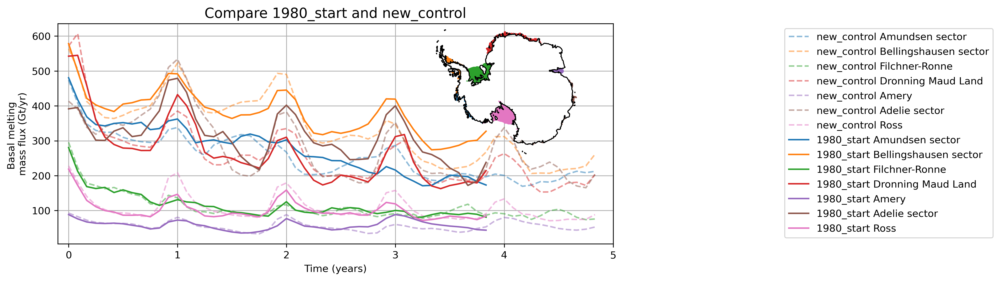

Amundsen melt increase wrt control,  1980_start
year       1      2      3      4     5    
[   nan   5.18   5.96 -11.08    nan]
Now doing lower_drag_coeff


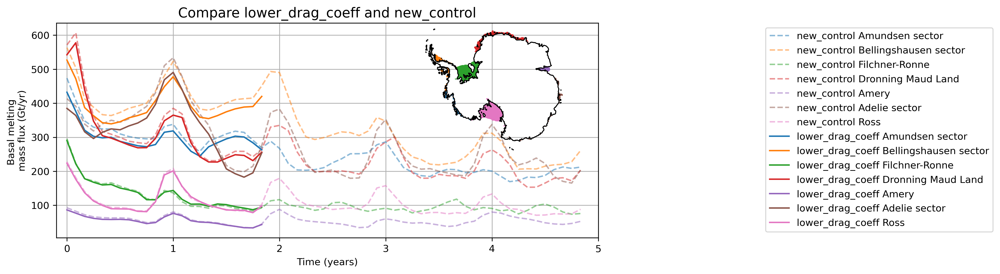

Amundsen melt increase wrt control,  lower_drag_coeff
year       1      2      3      4     5    
[  nan -4.61   nan   nan   nan]
Now doing smoothed_icebergs_from_rest


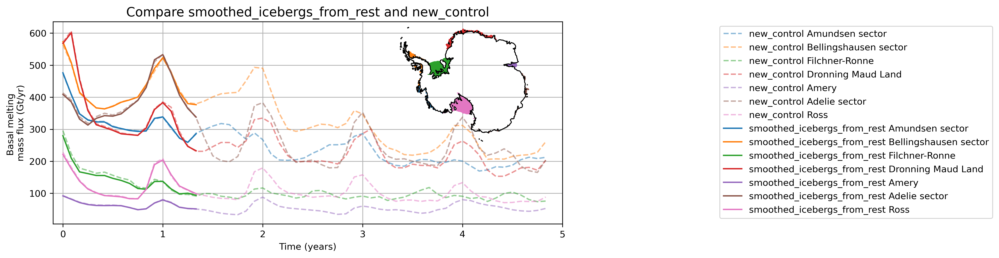

Amundsen melt increase wrt control,  smoothed_icebergs_from_rest
year       1      2      3      4     5    
[nan nan nan nan nan]
Now doing salt_rest_Amundsen


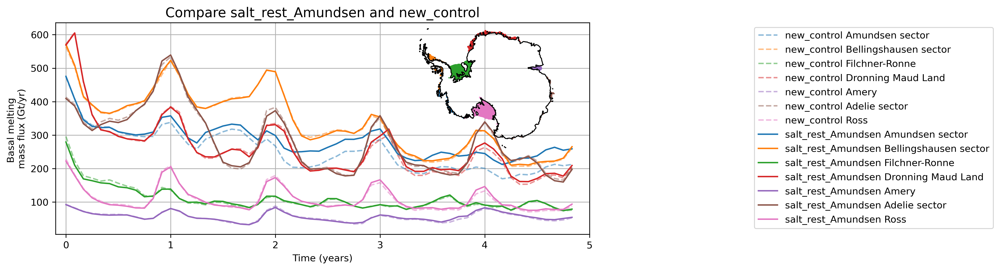

Amundsen melt increase wrt control,  salt_rest_Amundsen
year       1      2      3      4     5    
[  nan  6.07 16.37 17.52 24.14]
Now doing BearRidge_SI_only


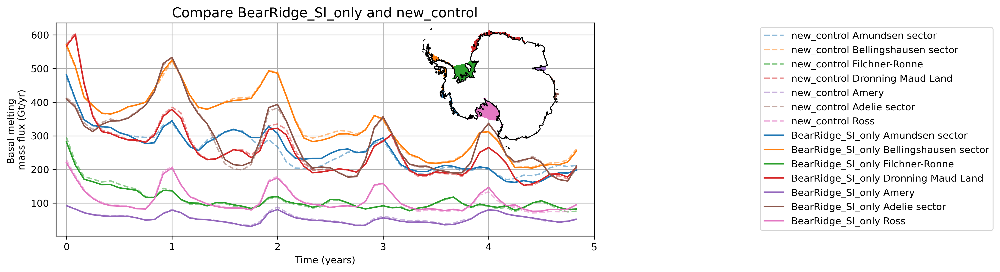

Amundsen melt increase wrt control,  BearRidge_SI_only
year       1      2      3      4     5    
[  nan  0.33  9.73  2.63 -6.65]
Now doing BearRidge_all


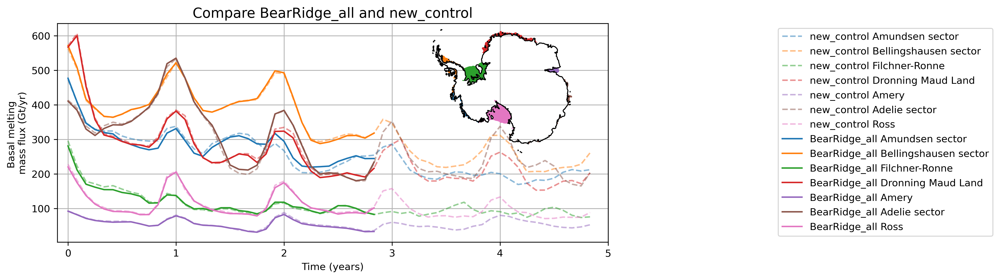

Amundsen melt increase wrt control,  BearRidge_all
year       1      2      3      4     5    
[  nan -2.03  5.25   nan   nan]
Now doing BearRidge_full_salt_rest


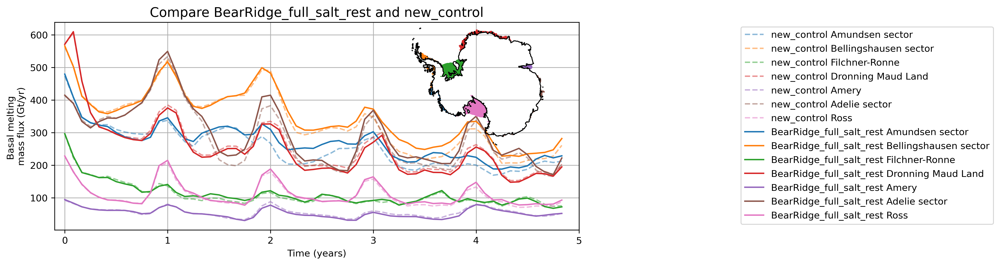

Amundsen melt increase wrt control,  BearRidge_full_salt_rest
year       1      2      3      4     5    
[  nan  2.76 15.3  11.2   8.56]
Now doing sea_ice_atm_drag


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:

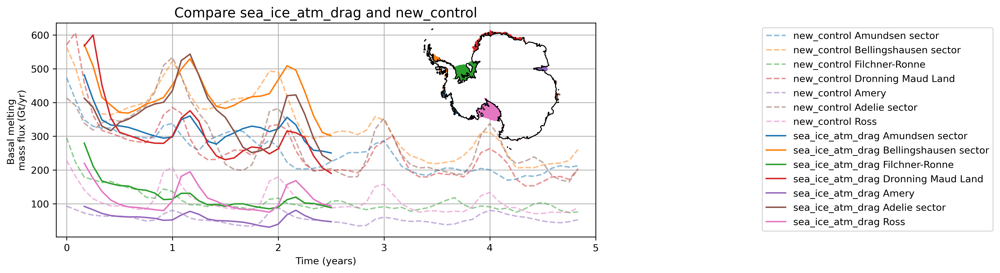

Amundsen melt increase wrt control,  sea_ice_atm_drag
year       1      2      3      4     5    
[ nan 6.26  nan  nan  nan]


In [20]:
for expt in expt_dict.keys():
    if (expt != 'old_control'):
        print('Now doing',expt)
        a,b,c = plot_total_melt_timeseries_regions(expt)
        result_dict[expt]['percent_incr'] = a
        result_dict[expt]['yearly_Amundsen_pert'] = b
        result_dict[expt]['yearly_Amundsen_control'] = c
        

In [27]:
# Fix old control
result_dict['old_control']['yearly_Amundsen_pert'] = result_dict['new_control']['yearly_Amundsen_control']
result_dict['old_control']['percent_incr'] = np.zeros(5)

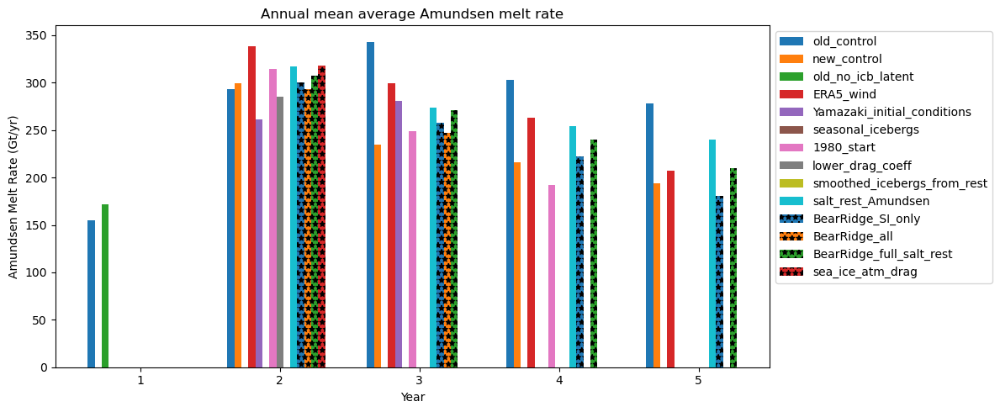

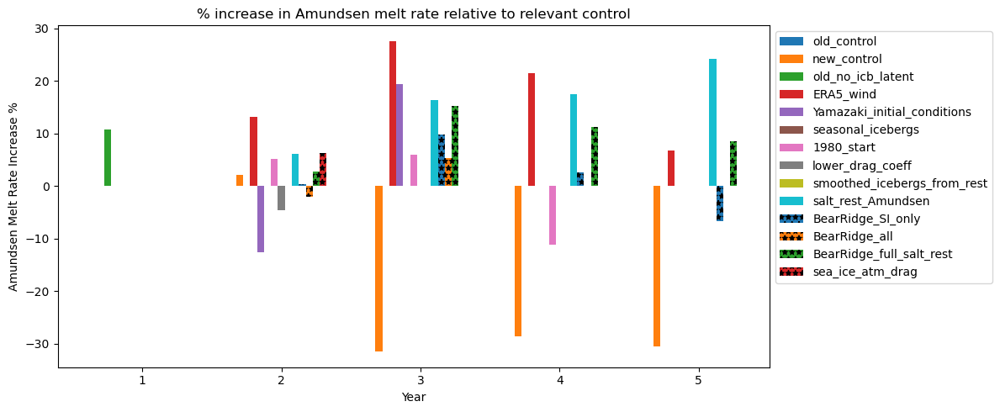

In [80]:
# Bar chart of Amundsen flux

fig, ax = plt.subplots(figsize=(12, 5))

bar_width = 0.05
x = np.arange(5) 

# Loop through the dictionary and plot each experiment
for i, (expt_name, content) in enumerate(result_dict.items()):
    data = content['yearly_Amundsen_pert']
    # Offset each experiment's bars so they sit side-by-side
    offset = i * bar_width
    if i >= 10:
        ax.bar(x + offset, data, width=bar_width, hatch = '**',label=expt_name)

    else:
        ax.bar(x + offset, data, width=bar_width, label=expt_name)

# Customize the chart labels and legend
ax.set_xlabel('Year')
ax.set_ylabel('Amundsen Melt Rate (Gt/yr)')
ax.set_title('Annual mean average Amundsen melt rate')
ax.set_xticks(x + 14*bar_width / 2)
ax.set_xticklabels(np.arange(1,6))
ax.legend(bbox_to_anchor = (1,1), loc = 'upper left')

# Display the plot
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))

bar_width = 0.05
x = np.arange(5) 

# Loop through the dictionary and plot each experiment
for i, (expt_name, content) in enumerate(result_dict.items()):
    data = content['percent_incr']
    # Offset each experiment's bars so they sit side-by-side
    offset = i * bar_width
    if i >= 10:
        ax.bar(x + offset, data, width=bar_width, hatch = '**',label=expt_name)

    else:
        ax.bar(x + offset, data, width=bar_width, label=expt_name)

# Customize the chart labels and legend
ax.set_xlabel('Year')
ax.set_ylabel('Amundsen Melt Rate Increase %')
ax.set_title('% increase in Amundsen melt rate relative to relevant control')
ax.set_xticks(x + 14*bar_width / 2)
ax.set_xticklabels(np.arange(1,6))
ax.legend(bbox_to_anchor = (1,1), loc = 'upper left')

# Display the plot
plt.tight_layout()
plt.show()

In [77]:
df = pd.DataFrame(result_dict).T
df2 = pd.DataFrame(expt_dict).T
df = pd.concat([df,df2],axis = 1)
df[['year1_percent_incr', 'year2_percent_incr', 'year3_percent_incr', 'year4_percent_incr', 'year5_percent_incr']] = pd.DataFrame(df['percent_incr'].tolist(), index=df.index)
df[['max yearly Amundsen melt from year 2']] = pd.DataFrame(np.nanmax(np.array(df['yearly_Amundsen_pert'].tolist())[:,1:],axis = 1), index=df.index)
df
df = df[['max yearly Amundsen melt from year 2','year1_percent_incr', 'year2_percent_incr', 'year3_percent_incr','year4_percent_incr','year5_percent_incr',
        'path','details','relevant_control','github_issue']]
df = df.sort_values(by='max yearly Amundsen melt from year 2',ascending=False)
df

/jobfs/181349607.gadi-pbs/ipykernel_1100874/2553718730.py:5: RuntimeWarning: All-NaN slice encountered
  df[['max yearly Amundsen melt from year 2']] = pd.DataFrame(np.nanmax(np.array(df['yearly_Amundsen_pert'].tolist())[:,1:],axis = 1), index=df.index)


,max yearly Amundsen melt from year 2,year1_percent_incr,year2_percent_incr,year3_percent_incr,year4_percent_incr,year5_percent_incr,path,details,relevant_control,github_issue
old_control,343.159912,0.00,0.00,0.00,0.00,0.00,/g/data/ik11/outputs/access-rom3-panan/MC_4km_...,old version of model run in Q1 2026,None,None
ERA5_wind,338.703430,NaN,13.13,27.58,21.55,6.83,/scratch/oz91/akm157/access-om3/archive/access...,Perturb winds in Amundsen region to match ERA5,new_control,https://github.com/claireyung/mom6-panAn-icesh...
sea_ice_atm_drag,318.122528,NaN,6.26,NaN,NaN,NaN,/scratch/oz91/fbd581/access-om3/archive/access...,BearRidge_SI_only plus reduced sea ice atmos drag,new_control,https://github.com/claireyung/mom6-panAn-icesh...
salt_rest_Amundsen,317.564545,NaN,6.07,16.37,17.52,24.14,/scratch/oz91/wf4500/access-om3/archive/ShelfR...,Salt restoring to Zhou 2026 (bias corrected fr...,new_control,https://github.com/claireyung/mom6-panAn-icesh...
1980_start,314.874298,NaN,5.18,5.96,-11.08,NaN,/scratch/oz91/akm157/access-om3/archive/access...,compare to 1975 start,new_control,https://github.com/claireyung/mom6-panAn-icesh...
BearRidge_full_salt_rest,307.640839,NaN,2.76,15.30,11.20,8.56,/scratch/oz91/wf4500/access-om3/archive/Restor...,BearRidge_all plus salinity restoring circumpo...,new_control,https://github.com/claireyung/mom6-panAn-icesh...
BearRidge_SI_only,300.376678,NaN,0.33,9.73,2.63,-6.65,/scratch/oz91/akm157/access-om3/archive/access...,Bear Ridge grounded iceberg land mask added to...,new_control,https://github.com/claireyung/mom6-panAn-icesh...
new_control,299.381195,NaN,2.19,-31.51,-28.61,-30.44,/scratch/oz91/akm157/access-om3/archive/access...,"updated model with new ICs, B-grid coastlines,...",old_control,https://github.com/claireyung/mom6-panAn-icesh...
BearRidge_all,293.311859,NaN,-2.03,5.25,NaN,NaN,/scratch/oz91/akm157/access-om3/archive/access...,Bear Ridge grounded iceberg land mask added to...,new_control,https://github.com/claireyung/mom6-panAn-icesh...
lower_drag_coeff,285.590546,NaN,-4.61,NaN,NaN,NaN,/scratch/oz91/akm157/access-om3/archive/access...,lower drag coeff from 0.009 to 0.007,new_control,https://github.com/claireyung/mom6-panAn-icesh...


In [79]:
print(df.to_markdown(index=True))

|                             |   max yearly Amundsen melt from year 2 |   year1_percent_incr |   year2_percent_incr |   year3_percent_incr |   year4_percent_incr |   year5_percent_incr | path                                                                                          | details                                                                                                            | relevant_control   | github_issue                                                      |
|:----------------------------|---------------------------------------:|---------------------:|---------------------:|---------------------:|---------------------:|---------------------:|:----------------------------------------------------------------------------------------------|:-------------------------------------------------------------------------------------------------------------------|:-------------------|:------------------------------------------------------------------|
| old_control       

# Repeat above for each of the Getz, Pine Island, Dotson, Crosson

In [81]:
ice_shelf_domains = {
                'Getz':{'xslice':slice(-135,-114.5),
                               'yslice':slice(-75.5,-73),
                       'Adusumilli mean': 124.1,
                       'Adusumilli unc': 40.9},
                'Dotson-Crosson':{'xslice':slice(-114.5,-109),
                               'yslice':slice(-76,-74),
                       'Adusumilli mean': 49.1,
                       'Adusumilli unc':13.4},
                'Thwaites':{'xslice':slice(-109,-103),
                               'yslice':slice(-76,-74),
                       'Adusumilli mean':81.9,
                       'Adusumilli unc':7.4},
                'Pine Island':{'xslice':slice(-102.5,-99),
                               'yslice':slice(-76,-74),
                       'Adusumilli mean':76.6,
                       'Adusumilli unc':8.6},
}

In [86]:
def plot_total_melt_timeseries_ice_shelf_regions(expt):

    mass_flux_control = load_mass_flux(expt_dict[expt]['relevant_control'])
    mass_flux_new = load_mass_flux(expt)
    
    # melt rate for different regions
    
    fig, axes = plt.subplots(figsize = (10,4),dpi = 300)
    s_to_yr = 365*24*60*60
    
    ax_inset = plt.axes([0.5,0.4,0.5,0.5],projection=ccrs.SouthPolarStereo())
    ax_inset.set_extent([-180, 180, -90, -65], ccrs.PlateCarree())
    ax_inset.coastlines()
    ax_inset.axis('off')
    
    # plot new sim
    yearly_arr = np.zeros([4,5])
    for i in np.arange(4):
        domain = ['Getz','Dotson-Crosson',
                  'Thwaites','Pine Island'][i]
        colors = ['C0','C1','C2','C3','C4','C5','C6','C7'][i]
        mass_flux1 = (mass_flux_control).mass_flux.sel(xT = ice_shelf_domains[domain]['xslice'],
                         yT = ice_shelf_domains[domain]['yslice'],
                                                      time = slice('1975-01-01','1985-01-01')).sum(['xT','yT'])/1e12*s_to_yr
        axes.plot(np.arange(len(mass_flux1))/12,mass_flux1.values,label = expt_dict[expt]['relevant_control']+ ' '+ domain,
                  color = colors, ls ='--', alpha = 0.5)
        mass_flux_mask = (mass_flux_control).mass_flux.sel(xT = ice_shelf_domains[domain]['xslice'],
                         yT = ice_shelf_domains[domain]['yslice']).isel(time = 0)
        mass_flux_mask = mass_flux_mask.where(mass_flux_mask!=0)
        mass_flux_mask = mass_flux_mask*0+1
        ax_inset.contourf(mass_flux_mask.xT,mass_flux_mask.yT,mass_flux_mask,
                            levels = [0.5,1.5], colors = colors, transform=ccrs.PlateCarree())
        yearly_control = mass_flux1.groupby('time.year')
        for j in np.arange(5):
            if yearly_control.count().isel(year = j) ==12:
                yearly_arr[i,j] = yearly_control.mean('time').isel(year = j).values
            else:
                yearly_arr[i,j] = np.nan

    yearly_arr_pert = np.zeros([4,5])    
    for i in np.arange(4):
        domain = ['Getz','Dotson-Crosson',
                  'Thwaites','Pine Island'][i]
        colors = ['C0','C1','C2','C3','C4','C5','C6','C7'][i]
        mass_flux2 = (mass_flux_new).mass_flux.sel(xT = ice_shelf_domains[domain]['xslice'],
                         yT = ice_shelf_domains[domain]['yslice']).sum(['xT','yT'])/1e12*s_to_yr
        axes.plot(np.arange(len(mass_flux2))/12,mass_flux2,label = expt + ' '+ domain,
                  color = colors, ls ='-')
        yearly_pert = mass_flux2.groupby('time.year')
        for j in np.arange(5):
            try:
                if yearly_pert.count().isel(year = j) ==12:
                    yearly_arr_pert[i,j] = yearly_pert.mean('time').isel(year = j).values
                else:
                    yearly_arr_pert[i,j] = np.nan
            except IndexError:
                yearly_arr_pert[i,j] = np.nan
    axes.legend(loc = 'upper left', ncol = 1, bbox_to_anchor = (1.3,1))
    
    axes.set_xlabel('Time (years)')
    axes.set_ylabel('Basal melting \nmass flux (Gt/yr)')
    axes.set_title('Compare '+expt+' and '+ expt_dict[expt]['relevant_control'], fontsize = 14)
    axes.grid()
    axes.set_xlim(-0.1,5)
    
    
    fig.subplots_adjust(wspace = 0.01)
    plt.show()

    percent_incr_melt = (yearly_arr_pert - yearly_arr)/yearly_arr * 100
    for i in np.arange(4):
        domain = ['Getz','Dotson-Crosson',
                  'Thwaites','Pine Island'][i]
        print(' melt increase wrt control, ',expt)
        print('year       1      2      3      4     5    ')
        print(np.round(percent_incr_melt[i,:],decimals=2))
    return np.round(percent_incr_melt,decimals=2), yearly_arr_pert, yearly_arr

In [87]:
inner_keys = ['percent_incr', 'yearly_Amundsen_pert', 'yearly_Amundsen_control']

ice_shelf_result_dict = {
    expt: {i_key: None for i_key in inner_keys} 
    for expt in expt_dict.keys()
}

ice_shelf_result_dict

{'old_control': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 'new_control': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 'old_no_icb_latent': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 'ERA5_wind': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 'Yamazaki_initial_conditions': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 'seasonal_icebergs': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 '1980_start': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 'lower_drag_coeff': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control': None},
 'smoothed_icebergs_from_rest': {'percent_incr': None,
  'yearly_Amundsen_pert': None,
  'yearly_Amundsen_control'

Now doing new_control


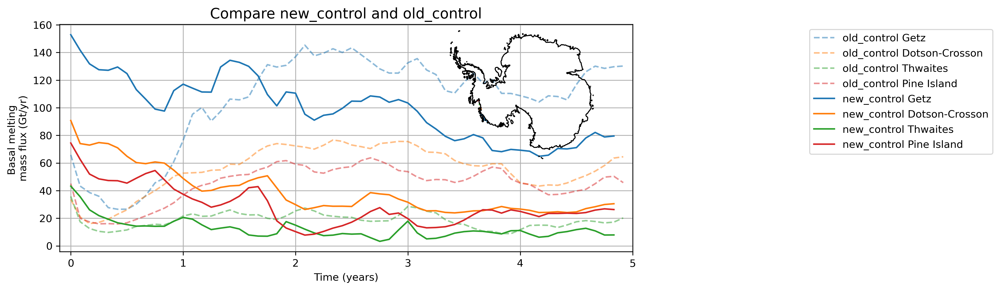

 melt increase wrt control,  new_control
year       1      2      3      4     5    
[   nan  10.51 -24.94 -30.12 -38.12]
 melt increase wrt control,  new_control
year       1      2      3      4     5    
[   nan -26.1  -56.88 -57.43 -47.7 ]
 melt increase wrt control,  new_control
year       1      2      3      4     5    
[   nan -42.12 -57.6  -44.34 -40.36]
 melt increase wrt control,  new_control
year       1      2      3      4     5    
[   nan -32.91 -72.49 -61.93 -43.14]
Now doing old_no_icb_latent


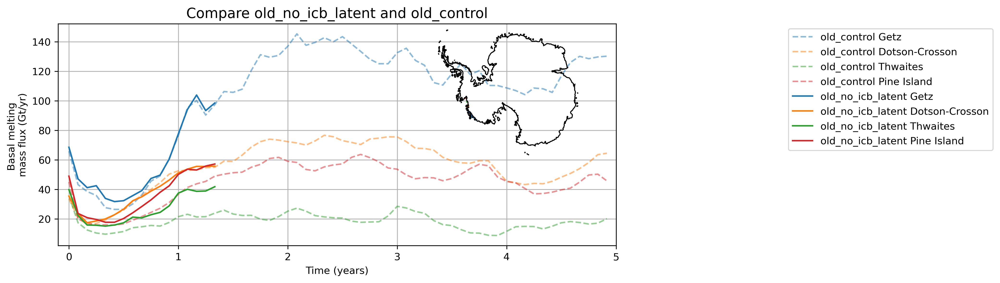

 melt increase wrt control,  old_no_icb_latent
year       1      2      3      4     5    
[8.98  nan  nan  nan  nan]
 melt increase wrt control,  old_no_icb_latent
year       1      2      3      4     5    
[0.23  nan  nan  nan  nan]
 melt increase wrt control,  old_no_icb_latent
year       1      2      3      4     5    
[40.55   nan   nan   nan   nan]
 melt increase wrt control,  old_no_icb_latent
year       1      2      3      4     5    
[23.9  nan  nan  nan  nan]
Now doing ERA5_wind


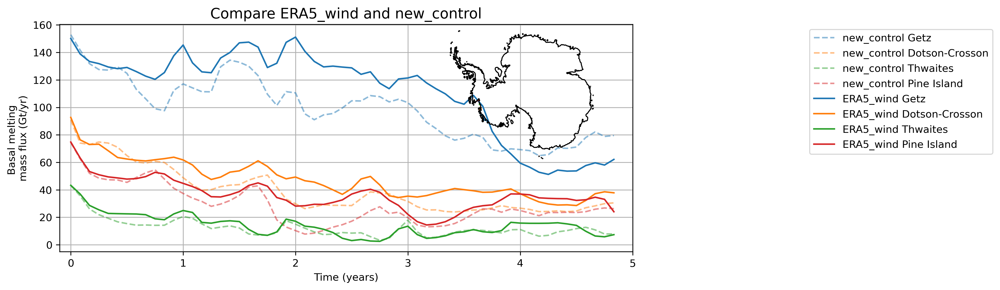

 melt increase wrt control,  ERA5_wind
year       1      2      3      4     5    
[   nan  15.02  27.99  26.54 -21.1 ]
 melt increase wrt control,  ERA5_wind
year       1      2      3      4     5    
[  nan 21.81 39.1  40.63 27.78]
 melt increase wrt control,  ERA5_wind
year       1      2      3      4     5    
[  nan 22.68 -4.25 -7.27 34.21]
 melt increase wrt control,  ERA5_wind
year       1      2      3      4     5    
[   nan  19.28 109.03  19.78  37.49]
Now doing Yamazaki_initial_conditions


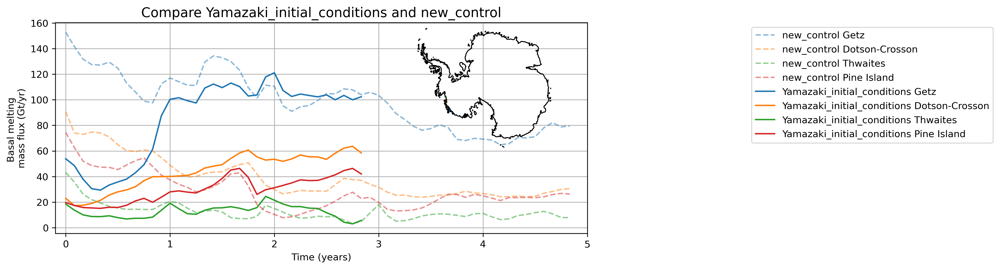

 melt increase wrt control,  Yamazaki_initial_conditions
year       1      2      3      4     5    
[   nan -12.59   3.35    nan    nan]
 melt increase wrt control,  Yamazaki_initial_conditions
year       1      2      3      4     5    
[  nan  5.67 78.25   nan   nan]
 melt increase wrt control,  Yamazaki_initial_conditions
year       1      2      3      4     5    
[  nan 12.86 47.49   nan   nan]
 melt increase wrt control,  Yamazaki_initial_conditions
year       1      2      3      4     5    
[   nan  -2.72 137.88    nan    nan]
Now doing seasonal_icebergs


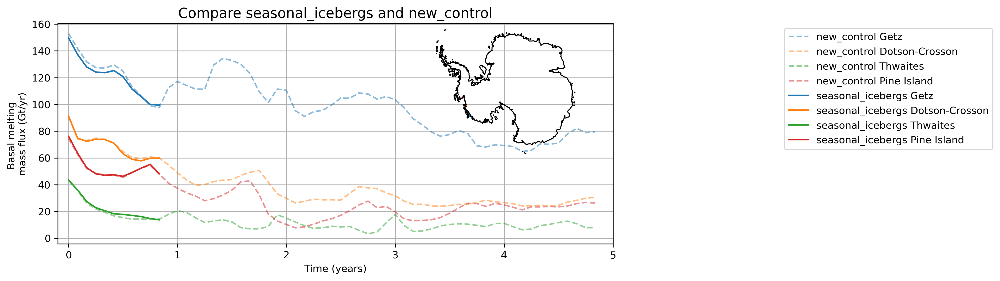

 melt increase wrt control,  seasonal_icebergs
year       1      2      3      4     5    
[nan nan nan nan nan]
 melt increase wrt control,  seasonal_icebergs
year       1      2      3      4     5    
[nan nan nan nan nan]
 melt increase wrt control,  seasonal_icebergs
year       1      2      3      4     5    
[nan nan nan nan nan]
 melt increase wrt control,  seasonal_icebergs
year       1      2      3      4     5    
[nan nan nan nan nan]
Now doing 1980_start


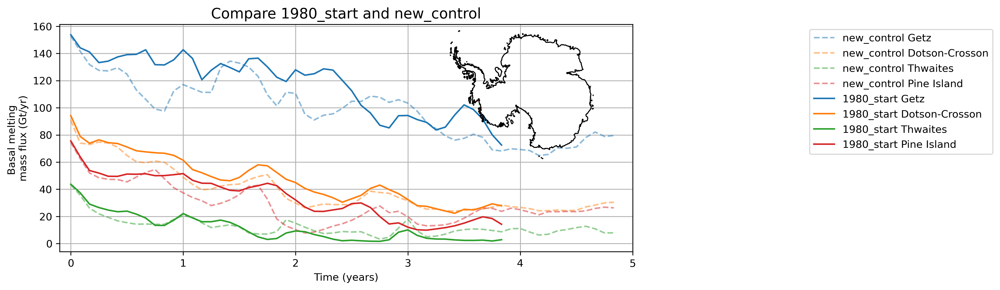

 melt increase wrt control,  1980_start
year       1      2      3      4     5    
[  nan 10.45 10.42  6.79   nan]
 melt increase wrt control,  1980_start
year       1      2      3      4     5    
[  nan 18.32 22.24  2.39   nan]
 melt increase wrt control,  1980_start
year       1      2      3      4     5    
[   nan   1.23 -50.88 -56.87    nan]
 melt increase wrt control,  1980_start
year       1      2      3      4     5    
[   nan  30.21  64.85 -27.22    nan]
Now doing lower_drag_coeff


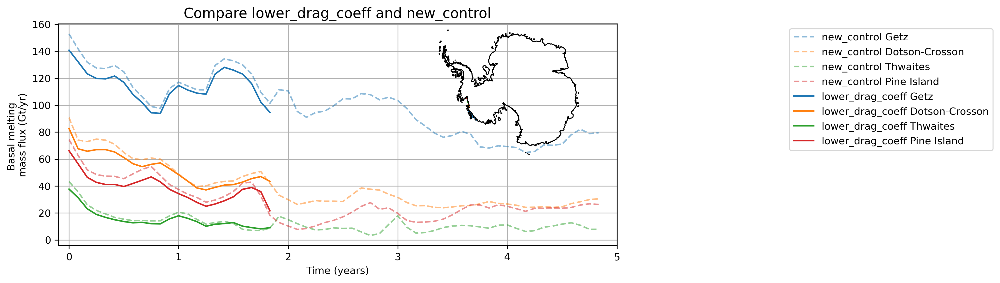

 melt increase wrt control,  lower_drag_coeff
year       1      2      3      4     5    
[ nan -4.4  nan  nan  nan]
 melt increase wrt control,  lower_drag_coeff
year       1      2      3      4     5    
[  nan -4.65   nan   nan   nan]
 melt increase wrt control,  lower_drag_coeff
year       1      2      3      4     5    
[  nan -5.02   nan   nan   nan]
 melt increase wrt control,  lower_drag_coeff
year       1      2      3      4     5    
[  nan -6.83   nan   nan   nan]
Now doing smoothed_icebergs_from_rest


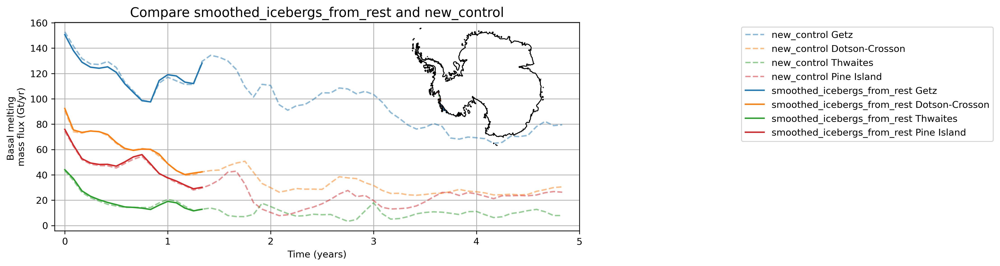

 melt increase wrt control,  smoothed_icebergs_from_rest
year       1      2      3      4     5    
[nan nan nan nan nan]
 melt increase wrt control,  smoothed_icebergs_from_rest
year       1      2      3      4     5    
[nan nan nan nan nan]
 melt increase wrt control,  smoothed_icebergs_from_rest
year       1      2      3      4     5    
[nan nan nan nan nan]
 melt increase wrt control,  smoothed_icebergs_from_rest
year       1      2      3      4     5    
[nan nan nan nan nan]
Now doing salt_rest_Amundsen


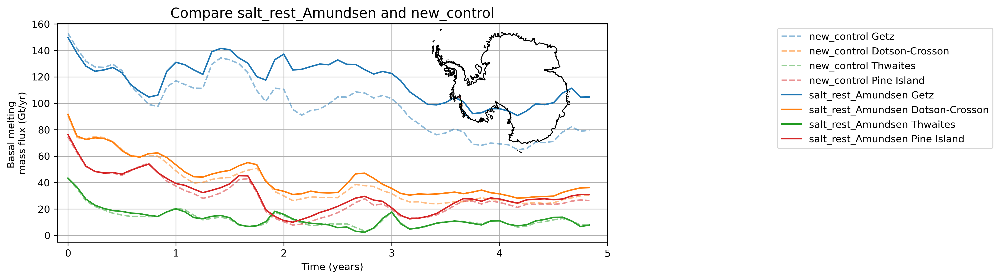

 melt increase wrt control,  salt_rest_Amundsen
year       1      2      3      4     5    
[  nan  8.95 25.99 25.33 37.9 ]
 melt increase wrt control,  salt_rest_Amundsen
year       1      2      3      4     5    
[  nan  8.94 15.28 21.92 19.05]
 melt increase wrt control,  salt_rest_Amundsen
year       1      2      3      4     5    
[  nan  1.63 -3.25 -1.16  5.6 ]
 melt increase wrt control,  salt_rest_Amundsen
year       1      2      3      4     5    
[  nan  8.45 20.63  5.98 14.17]
Now doing BearRidge_SI_only


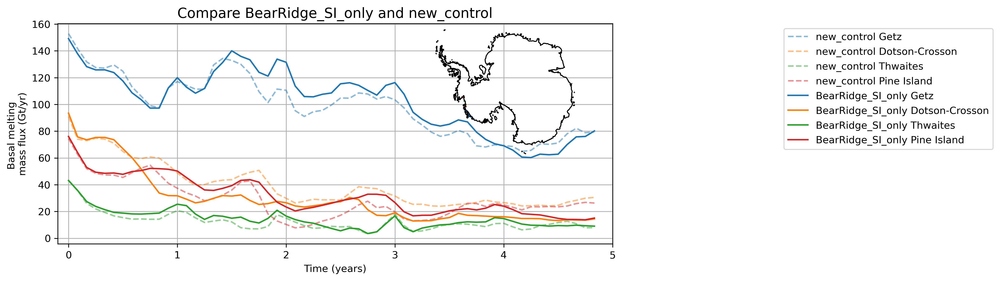

 melt increase wrt control,  BearRidge_SI_only
year       1      2      3      4     5    
[  nan  3.41 11.59  9.34 -5.99]
 melt increase wrt control,  BearRidge_SI_only
year       1      2      3      4     5    
[   nan -35.5  -20.1  -41.31 -45.11]
 melt increase wrt control,  BearRidge_SI_only
year       1      2      3      4     5    
[  nan 34.43  9.71  8.56 12.13]
 melt increase wrt control,  BearRidge_SI_only
year       1      2      3      4     5    
[   nan  23.04  67.92  11.02 -27.44]
Now doing BearRidge_all


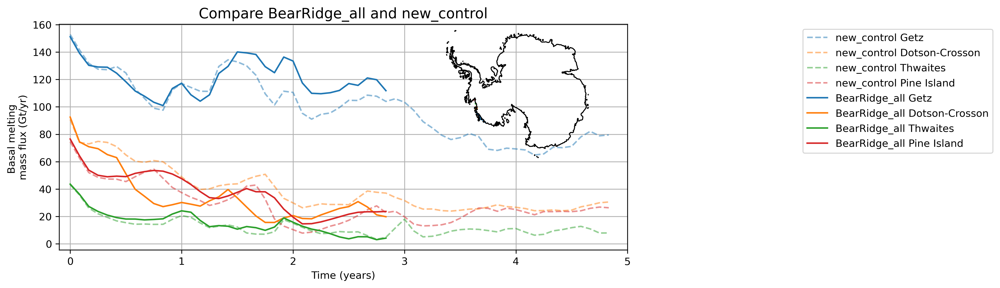

 melt increase wrt control,  BearRidge_all
year       1      2      3      4     5    
[  nan  3.6  15.23   nan   nan]
 melt increase wrt control,  BearRidge_all
year       1      2      3      4     5    
[   nan -39.1  -28.14    nan    nan]
 melt increase wrt control,  BearRidge_all
year       1      2      3      4     5    
[  nan 17.56 -7.61   nan   nan]
 melt increase wrt control,  BearRidge_all
year       1      2      3      4     5    
[  nan 15.65 27.19   nan   nan]
Now doing BearRidge_full_salt_rest


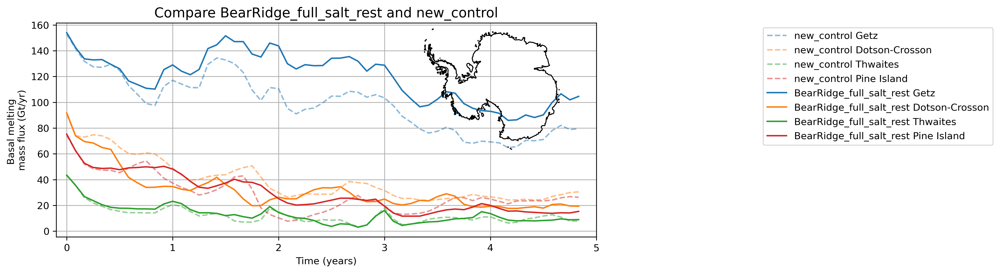

 melt increase wrt control,  BearRidge_full_salt_rest
year       1      2      3      4     5    
[  nan 14.21 29.64 28.33 30.33]
 melt increase wrt control,  BearRidge_full_salt_rest
year       1      2      3      4     5    
[   nan -30.16  -9.83 -12.77 -28.03]
 melt increase wrt control,  BearRidge_full_salt_rest
year       1      2      3      4     5    
[  nan 19.34 -6.48 -8.94  1.62]
 melt increase wrt control,  BearRidge_full_salt_rest
year       1      2      3      4     5    
[   nan  16.69  49.86 -17.31 -34.51]
Now doing sea_ice_atm_drag


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:

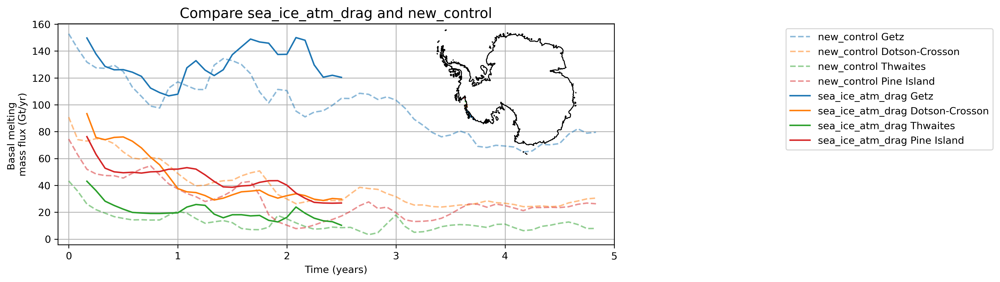

 melt increase wrt control,  sea_ice_atm_drag
year       1      2      3      4     5    
[  nan 14.28   nan   nan   nan]
 melt increase wrt control,  sea_ice_atm_drag
year       1      2      3      4     5    
[   nan -27.12    nan    nan    nan]
 melt increase wrt control,  sea_ice_atm_drag
year       1      2      3      4     5    
[  nan 44.59   nan   nan   nan]
 melt increase wrt control,  sea_ice_atm_drag
year       1      2      3      4     5    
[  nan 28.79   nan   nan   nan]


In [88]:
for expt in expt_dict.keys():
    if (expt != 'old_control'):
        print('Now doing',expt)
        a,b,c = plot_total_melt_timeseries_ice_shelf_regions(expt)
        ice_shelf_result_dict[expt]['percent_incr'] = a
        ice_shelf_result_dict[expt]['yearly_Amundsen_pert'] = b
        ice_shelf_result_dict[expt]['yearly_Amundsen_control'] = c


In [89]:
# Fix old control
ice_shelf_result_dict['old_control']['yearly_Amundsen_pert'] = ice_shelf_result_dict['new_control']['yearly_Amundsen_control']
ice_shelf_result_dict['old_control']['percent_incr'] = np.zeros([4,5])

Now plotting domain Getz


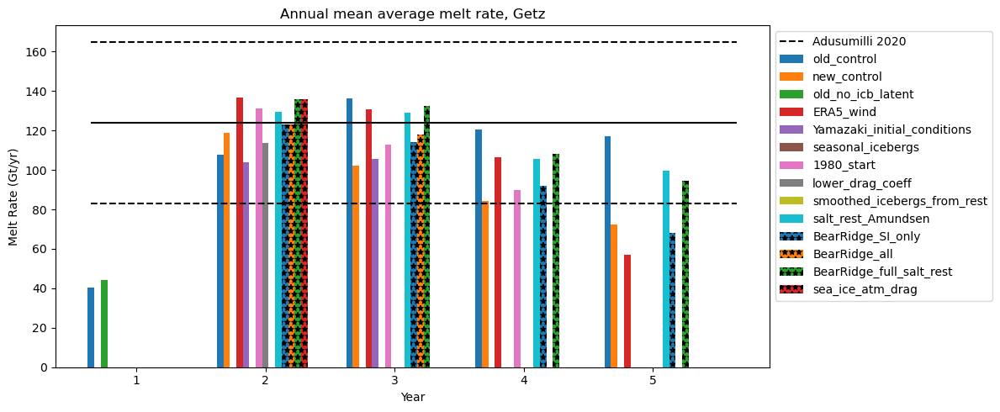

Now plotting domain Dotson-Crosson


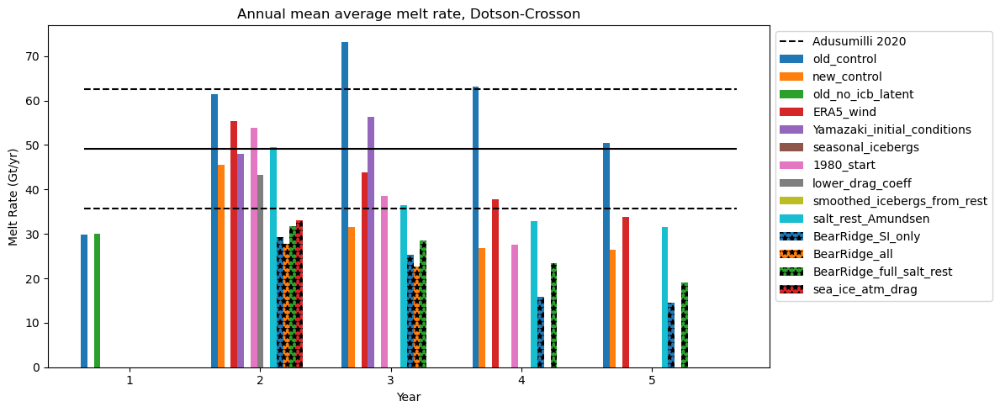

Now plotting domain Thwaites


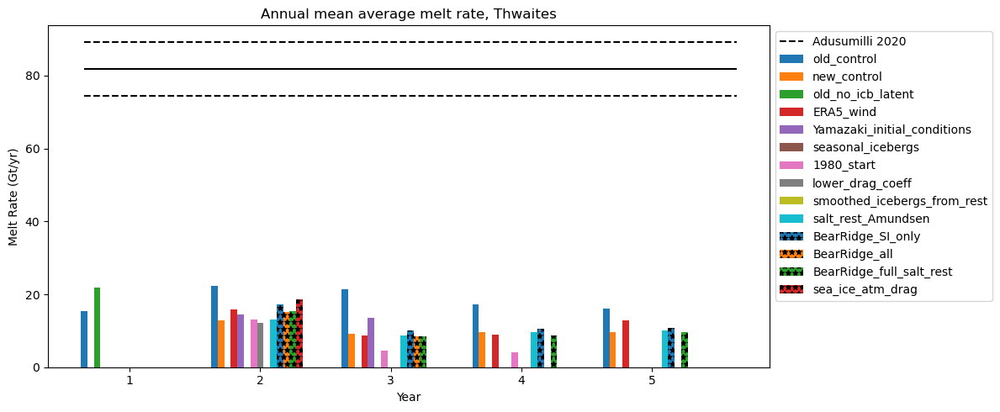

Now plotting domain Pine Island


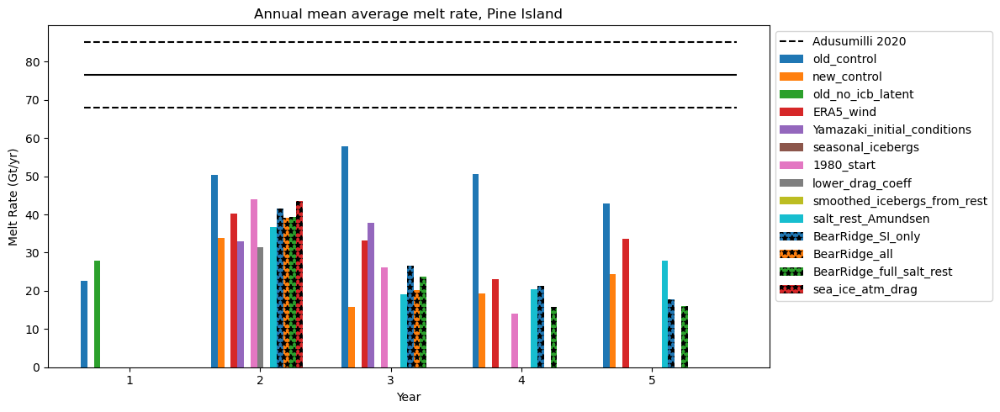

In [92]:
# Bar chart of Amundsen flux

for kk in np.arange(4):
    domain = ['Getz','Dotson-Crosson',
                  'Thwaites','Pine Island'][kk]
    print('Now plotting domain', domain)
    
    fig, ax = plt.subplots(figsize=(12, 5))
    
    bar_width = 0.05
    x = np.arange(5) 
    
    # Loop through the dictionary and plot each experiment
    for i, (expt_name, content) in enumerate(ice_shelf_result_dict.items()):
        data = content['yearly_Amundsen_pert'][kk,:]
        # Offset each experiment's bars so they sit side-by-side
        offset = i * bar_width
        if i >= 10:
            ax.bar(x + offset, data, width=bar_width, hatch = '**',label=expt_name)
    
        else:
            ax.bar(x + offset, data, width=bar_width, label=expt_name)
    # plot Adusumilli mean
    ax.hlines([ice_shelf_domains[domain]['Adusumilli mean'] - ice_shelf_domains[domain]['Adusumilli unc'],
               ice_shelf_domains[domain]['Adusumilli mean'],
               ice_shelf_domains[domain]['Adusumilli mean'] + ice_shelf_domains[domain]['Adusumilli unc']],
              0,5,
              colors = 'k',
              linestyles = ['--','-','--'],
             label = 'Adusumilli 2020')
    # Customize the chart labels and legend
    ax.set_xlabel('Year')
    ax.set_ylabel('Melt Rate (Gt/yr)')
    ax.set_title('Annual mean average melt rate, '+domain)
    ax.set_xticks(x + 14*bar_width / 2)
    ax.set_xticklabels(np.arange(1,6))
    ax.legend(bbox_to_anchor = (1,1), loc = 'upper left')
    
    # Display the plot
    plt.tight_layout()
    plt.show()


# Plot timeseries of bottom temperature on shelf

In [6]:
def load_tob(expt):
    base_path = expt_dict[expt]['path']+'output*/access-om3.mom6.2d.tob.1mon.mean.*.nc'
    tob = xr.open_mfdataset(glob.glob(base_path),decode_timedelta = True,
                                 chunks = {'time':1,'xh':1024,'yh':500})
    return tob

In [7]:
tob = load_tob('new_control')

shelf_mask = xr.open_dataset('/g/data/x77/cy8964/mom6/input/input-8km/150925/salt_restore_mask.nc')
shelf_mask['ny'] = tob.yh.values
shelf_mask['nx'] = tob.xh.values
shelf_mask = 1 - shelf_mask.rename({'nx':'xh','ny':'yh'}).mask.squeeze()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 47.65 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


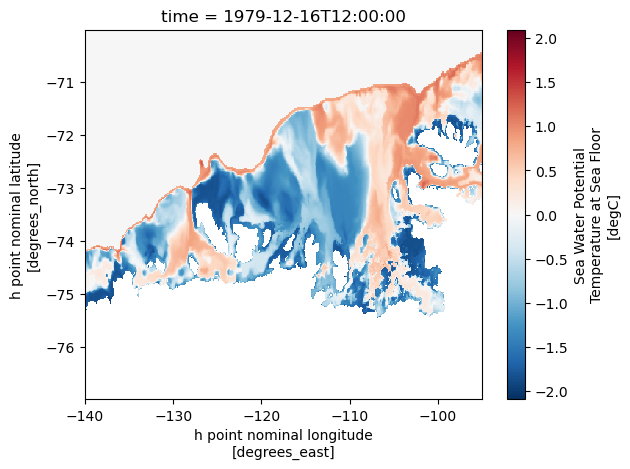

In [11]:
tob_shelf = (tob.tob*shelf_mask).sel(xh = slice(-140,-95),yh = slice(-77,-70))
tob_shelf.isel(time = -1).plot()

Now doing old_control


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 48.46 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Now doing new_control


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 47.66 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Now doing old_no_icb_latent


...

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 47.60 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Now doing BearRidge_full_salt_rest


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 47.66 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Now doing sea_ice_atm_drag


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.10/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 47.63 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


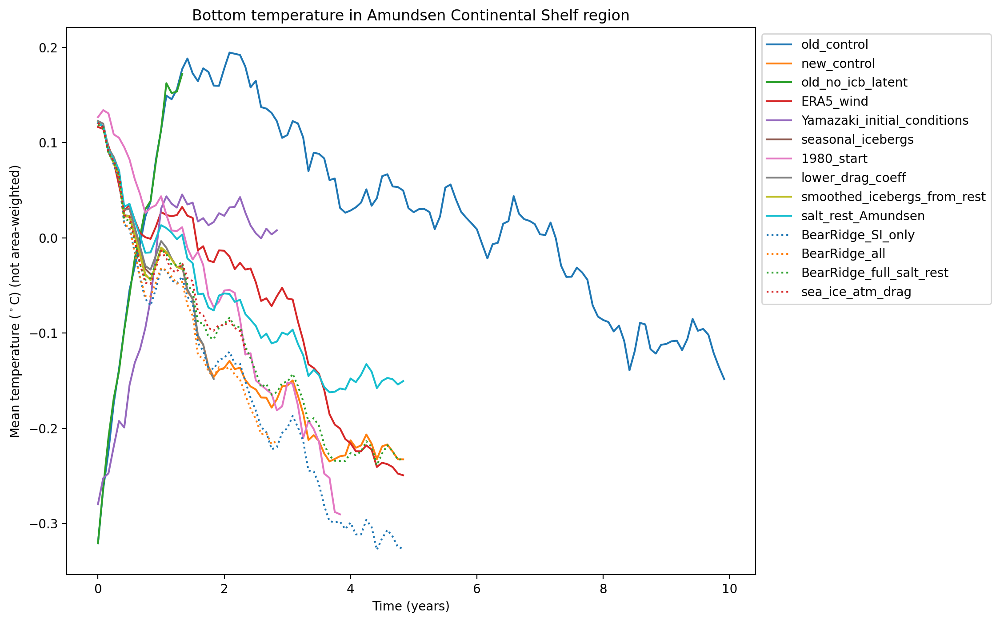

In [15]:
fig, axes = plt.subplots(figsize = (10,8),dpi = 200)
i = 0
for expt in expt_dict.keys():
    i = i+1
    tob = load_tob(expt)
    if expt == 'sea_ice_atm_drag':
        # need to delete first two outputs
        tob = tob.isel(time = np.arange(2,len(tob.time)))
    print('Now doing',expt)
    tob_shelf = (tob.tob.sel(time = slice('1975-01-01','1990-01-01'))*shelf_mask).sel(xh = slice(-140,-95),yh = slice(-77,-70)).mean(['xh','yh'])
    
    #crude spatial mean (not area weighted)
    if i>10:
        axes.plot(np.arange(len(tob_shelf.time))/12,tob_shelf.values,
                          label = expt,linestyle = 'dotted')
    else:
        axes.plot(np.arange(len(tob_shelf.time))/12,tob_shelf.values,
                          label = expt,linestyle = '-')
axes.set_xlabel('Time (years)')
axes.set_ylabel('Mean temperature ($^\circ$C) (not area-weighted)')
axes.set_title('Bottom temperature in Amundsen Continental Shelf region')
axes.legend(bbox_to_anchor = (1,1), loc = 'upper left')
                            